## **Projeto - Diagnóstico de cancro da mama com CNNs e Active Learning**
---
Inteligência Artificial Centrada no Humano

Faculdade de Ciências e Tecnologia da Universidade de Coimbra | Mestrado em Engenharia e Ciência de Dados


Alunos: Eduardo Cardoso (2021226956) , Mafalda Nunes (2020236933), Matilde Reis (2021237887)

In [ ]:
# Importar bibliotecas

import os
import time
import numpy as np
from PIL import Image
from IPython.display import display
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
path = "/content/drive/My Drive/img"

Mounted at /content/drive


In [ ]:
# array com os nomes das imagens
img_names = np.array(os.listdir(path))

In [ ]:
# array com as matrizes das imagens, transformadas para uma dimensão fixa (224x224) e normalizadas
images = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)))/255.0 for name in img_names]
images = np.array(images)

In [ ]:
images.shape

(780, 224, 224)

In [ ]:
# array com as classes
labels0 = np.array([name.split(" ")[0] for name in img_names])

### Análise Exploratória de Dados e pré-processamento

[133, 437, 210]


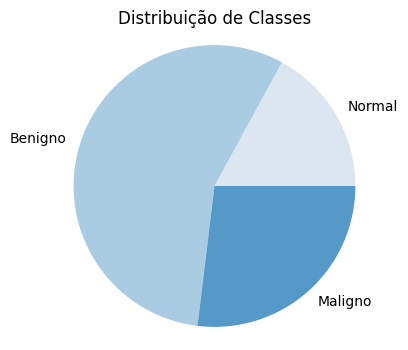

In [ ]:
# Verificar o balanceamento dos dados

classes = [len(np.where(labels0=="normal")[0]) , len(np.where(labels0=="benign")[0]), len(np.where(labels0=="malignant")[0]) ]
print(classes)

colors = ['#dce6f1', '#a9cce3', '#5499c7']

plt.figure(figsize=(4, 4))
plt.pie(classes, labels=["Normal", "Benigno","Maligno"], colors=colors)
plt.title('Distribuição de Classes')
plt.axis('equal')
plt.show()

In [ ]:
# Fazer o balanceamento dos dados

# Classe: normal -----------------------------------------

# Rodar 180 graus
normal_img_180 = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).rotate(180))/255.0 for name in img_names if "normal" in name]
normal_img_180_label = np.array(["normal"] * len(normal_img_180))
# Rodar 90 graus
normal_img_90 = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).rotate(90))/255.0 for name in img_names if "normal" in name]
normal_img_90_label = np.array(["normal"] * len(normal_img_90))
# Reflexão vertical (imagens originais)
normal_img_vert_flip = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).transpose(Image.FLIP_TOP_BOTTOM))/255.0
                        for name in img_names if "normal" in name]
normal_img_vert_flip_label = np.array(["normal"] * len(normal_img_vert_flip))
# Reflexão vertical (imagens rodadas 180 graus)
normal_img_180_vert_flip = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).rotate(180).transpose(Image.FLIP_TOP_BOTTOM))/255.0
                        for name in img_names if "normal" in name]
normal_img_180_vert_flip_label = np.array(["normal"] * len(normal_img_180_vert_flip))
# Reflexão vertical (imagens rodadas 90 graus)
normal_img_90_vert_flip = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).rotate(90).transpose(Image.FLIP_TOP_BOTTOM))/255.0
                        for name in img_names if "normal" in name]
normal_img_90_vert_flip_label = np.array(["normal"] * len(normal_img_90_vert_flip))

# Classe: maligno ----------------------------------------

# Rodar 180 graus
malign_img_180 = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).rotate(180))/255.0 for name in img_names if "malignant" in name]
malign_img_180_label = np.array(["malignant"] * len(malign_img_180))
# Reflexão vertical (imagens originais)
malign_img_vert_flip = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).transpose(Image.FLIP_TOP_BOTTOM))/255.0
                        for name in img_names if "malignant" in name]
malign_img_vert_flip_label = np.array(["malignant"] * len(malign_img_vert_flip))
# Reflexão vertical (imagens rodadas 180 graus)
malign_img_180_vert_flip = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).rotate(180).transpose(Image.FLIP_TOP_BOTTOM))/255.0
                        for name in img_names if "malignant" in name]
malign_img_180_vert_flip_label = np.array(["malignant"] * len(malign_img_180_vert_flip))

# Classe: benigno ----------------------------------------

# Reflexão vertical
benign_img_vert_flip = [np.asarray(Image.open(path + "/" + name).convert('L').resize((224,224)).transpose(Image.FLIP_TOP_BOTTOM))/255.0
                        for name in img_names if "benign" in name]
benign_img_vert_flip_label = np.array(["benign"] * len(benign_img_vert_flip))

# Adicionar novos dados aos existentes
images = np.append(images, np.array(normal_img_180), axis = 0)
images = np.append(images, np.array(normal_img_90), axis = 0)
images = np.append(images, np.array(normal_img_vert_flip), axis = 0)
images = np.append(images, np.array(normal_img_180_vert_flip), axis = 0)
images = np.append(images, np.array(normal_img_90_vert_flip), axis = 0)
images = np.append(images, np.array(malign_img_180), axis = 0)
images = np.append(images, np.array(malign_img_vert_flip), axis = 0)
images = np.append(images, np.array(malign_img_180_vert_flip), axis = 0)
images = np.append(images, np.array(benign_img_vert_flip), axis = 0)

labels0 = np.append(labels0, normal_img_180_label)
labels0 = np.append(labels0, normal_img_90_label)
labels0 = np.append(labels0, normal_img_vert_flip_label)
labels0 = np.append(labels0, normal_img_180_vert_flip_label)
labels0 = np.append(labels0, normal_img_90_vert_flip_label)
labels0 = np.append(labels0, malign_img_180_label)
labels0 = np.append(labels0, malign_img_vert_flip_label)
labels0 = np.append(labels0, malign_img_180_vert_flip_label)
labels0 = np.append(labels0, benign_img_vert_flip_label)

In [ ]:
print(images.shape)
print(labels0.shape)

(2512, 224, 224)
(2512,)


[798, 874, 840]


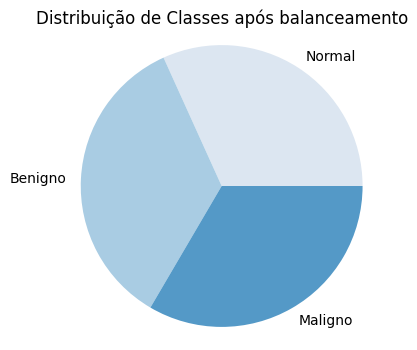

In [ ]:
# Fazer o gráfico após o balanceamento

classes = [len(np.where(labels0=="normal")[0]) , len(np.where(labels0=="benign")[0]), len(np.where(labels0=="malignant")[0]) ]
print(classes)

colors = ['#dce6f1', '#a9cce3', '#5499c7']

plt.figure(figsize=(4, 4))
plt.pie(classes, labels=["Normal", "Benigno","Maligno"], colors=colors)
plt.title('Distribuição de Classes após balanceamento')
plt.axis('equal')
plt.show()

In [ ]:
# Converter labels em valores numéricos

labels = np.array([0 if lbl == "normal" else
                   1 if lbl == "benign" else
                   2 for lbl in labels0])

In [ ]:
# Dividir os dados em teste e treino as imagens e as labels

x_train, x_test, y_train, y_test = train_test_split(images, labels, test_size = 0.2, stratify=labels, random_state=1)

x_train, x_test = np.array(x_train), np.array(x_test)
y_train, y_test = np.array(y_train), np.array(y_test)

In [ ]:
print(f"Conjunto de Treino: {x_train.shape}, Conjunto de teste: {x_test.shape}") # (2009, 224, 224): 2009 imagens de treino com dimensão 224x224
print(f"Labels de treino: {y_train.shape}, Labels de teste: {y_test.shape}")

Conjunto de Treino: (2009, 224, 224), Conjunto de teste: (503, 224, 224)
Labels de treino: (2009,), Labels de teste: (503,)


### Implementação do modelo

In [ ]:
!pip install modAL-python
!pip install scikeras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 kB 6.0 MB/s eta 0:00:00


In [ ]:
from tensorflow.keras.utils import to_categorical
from modAL.models import ActiveLearner
from modAL.uncertainty import entropy_sampling, uncertainty_sampling, margin_sampling
from scikeras.wrappers import KerasClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.optimizers import Adam, SGD
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

In [ ]:
# Passar as classes para o formato one-hot
y_train_one_hot = to_categorical(y_train, num_classes=3)
y_test_one_hot = to_categorical(y_test, num_classes=3)

In [ ]:
# Construção do modelo de CNN

model = Sequential([
        Input((224, 224, 1)),
        Conv2D(32, (4, 4), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Conv2D(64, (4, 4), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),
        Dropout(0.3),

        Conv2D(128, (4, 4), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),
        Dropout(0.3),

        Conv2D(32, (4, 4), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Flatten(),
        Dense(32, activation='sigmoid'),

        Dense(3, activation='softmax')  # 3 classes
    ])

model.compile(optimizer=Adam(learning_rate=0.00001), loss='categorical_crossentropy', metrics=['accuracy'])

# Treinar o modelo
epochs_hist = model.fit(x_train, y_train_one_hot, epochs = 15,  verbose = 1, validation_split = 0.2)

Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 282ms/step - accuracy: 0.3368 - loss: 1.1439 - val_accuracy: 0.3532 - val_loss: 1.1979
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 0.4435 - loss: 1.0530 - val_accuracy: 0.3532 - val_loss: 1.2705
Epoch 3/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.5205 - loss: 1.0035 - val_accuracy: 0.3532 - val_loss: 1.3327
Epoch 4/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.5532 - loss: 0.9563 - val_accuracy: 0.3532 - val_loss: 1.3861
Epoch 5/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.5837 - loss: 0.9414 - val_accuracy: 0.3532 - val_loss: 1.4361
Epoch 6/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.5853 - loss: 0.9265 - val_accuracy: 0.3532 - val_loss: 1.4887
Epoch 7/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.5709 - loss: 0.9193 - val_accuracy: 0.3532 - val_loss: 1.5231
Epoch 8/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.5821 - loss: 0.9002 - val_accuracy: 0.3532 

In [ ]:
# Accuracy obtida

predicted = model.predict(x_test)
y_true = np.argmax(y_test_one_hot,axis = 1)
y_pred = np.argmax(predicted, axis=1)

accuracy_score(y_true, y_pred)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


0.4592445328031809